# 👖 Variational Autoencoders - Fashion-MNIST

##### Week2 01341677 Xuezhengwu Rao

##### Environment: Python 3.12.13, Jupyter Notebook
##### Packages: TensorFlow, Keras, NumPy, scikit-learn, Matplotlib, SciPy, pandas, IPython
##### Random seed: 2026

##### Reference:
##### Foster, D. (2023). Generative deep learning: teaching machines to paint, write, compose, and play(2nd ed). O'Reilly Media.
##### Foster, D. (2023). Generative_Deep_Learning_2nd_Edition. GitHub. https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
import tensorflow.keras.backend as K
from tensorflow.keras import (
    layers,
    models,
    datasets,
    losses,
    optimizers,
    metrics,
)

from scipy.stats import norm

In [2]:
import sys
import pandas as pd
import sklearn
from sklearn.manifold import TSNE

#set the random seed
random_seed = 2026
tf.keras.utils.set_random_seed(random_seed)

#record the environment
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Random seed:", random_seed)

#Adapted from Foster's notebooks/utils.py.
def display(
    images, n=10, size=(20, 3), cmap="gray_r", as_type="float32"
):
    """
    Display the first n images.
    """
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0

    plt.figure(figsize=size)
    for i in range(n):
        _ = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].astype(as_type), cmap=cmap)
        plt.axis("off")

    plt.show()

Python: 3.12.13
TensorFlow: 2.21.0
NumPy: 2.5.1
Scikit-learn: 1.9.0
Random seed: 2026


# Task 1: Baseline Run

## 0. Parameters <a name="parameters"></a>

In [3]:
IMAGE_SIZE = 32
BATCH_SIZE = 100
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 2
EPOCHS = 5
BETA = 500

## 1. Prepare the data <a name="prepare"></a>

In [4]:
# Load the data
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()

In [5]:
# Preprocess the data


def preprocess(imgs):
    """
    Normalize and reshape the images
    """
    imgs = imgs.astype("float32") / 255.0
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=0.0)
    imgs = np.expand_dims(imgs, -1)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

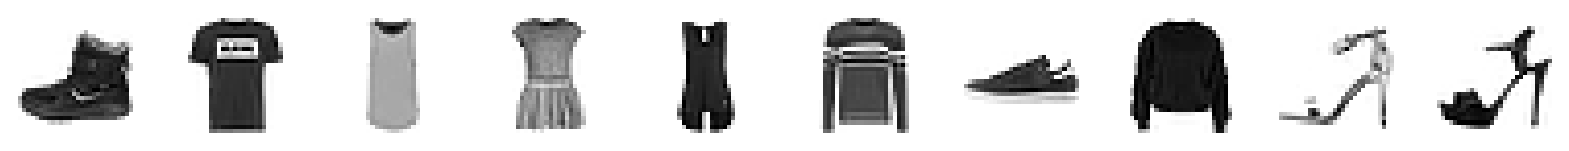

In [6]:
# Show some items of clothing from the training set
display(x_train)

## 2. Build the variational autoencoder <a name="build"></a>

In [7]:
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = K.random_normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

In [8]:
# Encoder
encoder_input = layers.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, 1), name="encoder_input"
)
x = layers.Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(
    encoder_input
)
x = layers.Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
shape_before_flattening = K.int_shape(x)[1:]  # the decoder will need this!

x = layers.Flatten()(x)
z_mean = layers.Dense(EMBEDDING_DIM, name="z_mean")(x)
z_log_var = layers.Dense(EMBEDDING_DIM, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

encoder = models.Model(encoder_input, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 32, 32, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 16, 16,    │        320 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 8, 8, 64)  │     18,496 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 4, 4, 128) │     73,856 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 2048)      │          0 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │      4,098 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │      4,098 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 100,868 (394.02 KB)

 Trainable params: 100,868 (394.02 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Decoder
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape_before_flattening)))(decoder_input)
x = layers.Reshape(shape_before_flattening)(x)
x = layers.Conv2DTranspose(
    128, (3, 3), strides=2, activation="relu", padding="same"
)(x)
x = layers.Conv2DTranspose(
    64, (3, 3), strides=2, activation="relu", padding="same"
)(x)
x = layers.Conv2DTranspose(
    32, (3, 3), strides=2, activation="relu", padding="same"
)(x)
decoder_output = layers.Conv2D(
    1,
    (3, 3),
    strides=1,
    activation="sigmoid",
    padding="same",
    name="decoder_output",
)(x)

decoder = models.Model(decoder_input, decoder_output)
decoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 32, 32, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 246,273 (962.00 KB)

 Trainable params: 246,273 (962.00 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
class VAE(models.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs):
        """Call the model on a particular input."""
        z_mean, z_log_var, z = self.encoder(inputs)
        reconstruction = self.decoder(z)
        return z_mean, z_log_var, reconstruction

    def train_step(self, data):
        """Step run during training."""
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            z_mean, z_log_var, reconstruction = self(data)
            reconstruction_loss = tf.reduce_mean(
                BETA
                * losses.binary_crossentropy(
                    data, reconstruction, axis=(1, 2, 3)
                )
            )
            kl_loss = tf.reduce_mean(
                tf.reduce_sum(
                    -0.5
                    * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)),
                    axis=1,
                )
            )
            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        """Step run during validation."""
        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, reconstruction = self(data)
        reconstruction_loss = tf.reduce_mean(
            BETA
            * losses.binary_crossentropy(data, reconstruction, axis=(1, 2, 3))
        )
        kl_loss = tf.reduce_mean(
            tf.reduce_sum(
                -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)),
                axis=1,
            )
        )
        total_loss = reconstruction_loss + kl_loss

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {m.name: m.result() for m in self.metrics}

In [11]:
# Create a variational autoencoder
vae = VAE(encoder, decoder)

## 3. Train the variational autoencoder <a name="train"></a>

In [12]:
# Compile the variational autoencoder
optimizer = optimizers.Adam(learning_rate=0.0005)
vae.compile(optimizer=optimizer)

In [13]:
baseline_history = vae.fit(
    x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=2,
)

Epoch 1/5
600/600 - 33s - 54ms/step - kl_loss: 4.3854 - reconstruction_loss: 157.9510 - total_loss: 162.3365 - val_kl_loss: 4.9378 - val_reconstruction_loss: 133.6799 - val_total_loss: 138.6177
Epoch 2/5
600/600 - 33s - 55ms/step - kl_loss: 5.0029 - reconstruction_loss: 131.0907 - total_loss: 136.0935 - val_kl_loss: 4.9879 - val_reconstruction_loss: 130.1553 - val_total_loss: 135.1433
Epoch 3/5
600/600 - 33s - 55ms/step - kl_loss: 5.0964 - reconstruction_loss: 129.0546 - total_loss: 134.1510 - val_kl_loss: 5.3094 - val_reconstruction_loss: 128.7813 - val_total_loss: 134.0907
Epoch 4/5
600/600 - 35s - 59ms/step - kl_loss: 5.1462 - reconstruction_loss: 128.0465 - total_loss: 133.1927 - val_kl_loss: 5.3616 - val_reconstruction_loss: 128.2930 - val_total_loss: 133.6545
Epoch 5/5
600/600 - 36s - 60ms/step - kl_loss: 5.2126 - reconstruction_loss: 127.4052 - total_loss: 132.6178 - val_kl_loss: 5.3643 - val_reconstruction_loss: 127.8670 - val_total_loss: 133.2314


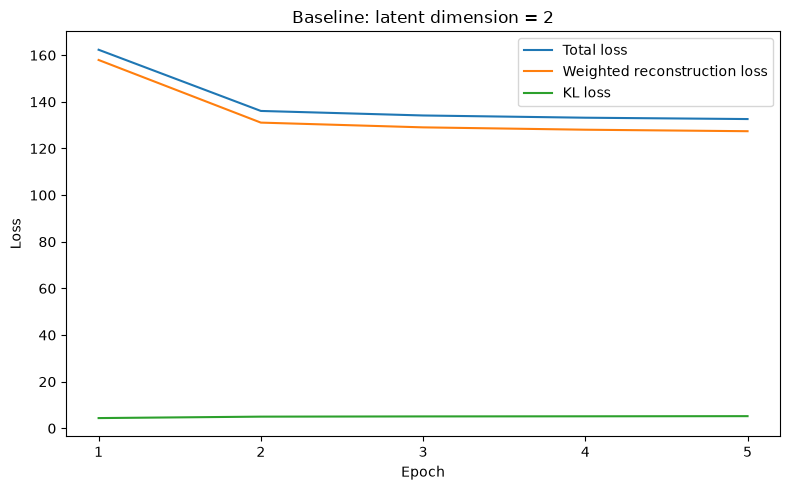

In [14]:
#compare a 2D latent space with two larger latent spaces
latent_dims = [2, 8, 16]

#keep the baseline model and its loss values
vae_models = {EMBEDDING_DIM: vae}
loss_history = {EMBEDDING_DIM: baseline_history.history}
epoch_numbers = range(1, EPOCHS + 1)

#plot the three baseline losses on the same figure
plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, loss_history[2]["total_loss"], label="Total loss")
plt.plot(epoch_numbers, loss_history[2]["reconstruction_loss"], label="Weighted reconstruction loss")
plt.plot(epoch_numbers, loss_history[2]["kl_loss"], label="KL loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epoch_numbers))
plt.title("Baseline: latent dimension = 2")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Reconstruct using the variational autoencoder <a name="reconstruct"></a>

In [15]:
# Select a subset of the test set
n_to_predict = len(x_test)
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Example real clothing items


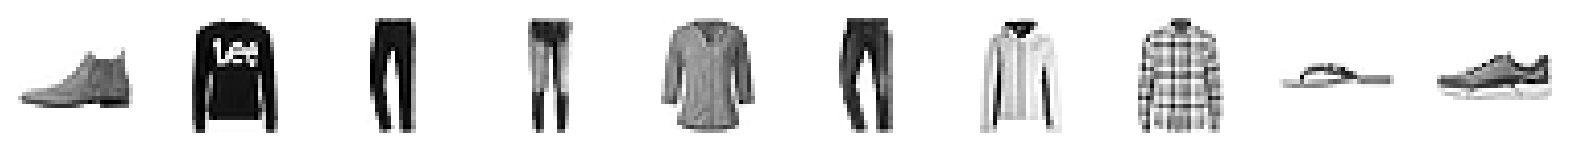

Reconstructions


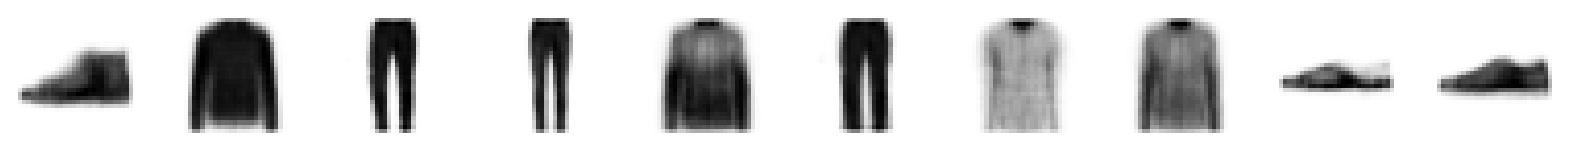

In [16]:
# Create autoencoder predictions and display
z_mean, z_log_var, reconstructions = vae.predict(example_images)
print("Example real clothing items")
display(example_images)
print("Reconstructions")
display(reconstructions)

## 4. Embed using the encoder <a name="encode"></a>

In [17]:
# Encode the example images
z_mean, z_var, z = encoder.predict(example_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [18]:
# Some examples of the embeddings
print(z[:10])

[[ 1.374103   -1.2136943 ]
 [ 0.19716775  0.56129014]
 [-1.5464059   2.5256526 ]
 [-2.3656473   0.81615096]
 [-0.11032403  0.02831022]
 [-1.045569    1.8102269 ]
 [-0.8603595  -0.73039865]
 [-0.3768613  -0.09277502]
 [-1.0707104  -2.6866248 ]
 [ 0.16069612 -1.966576  ]]


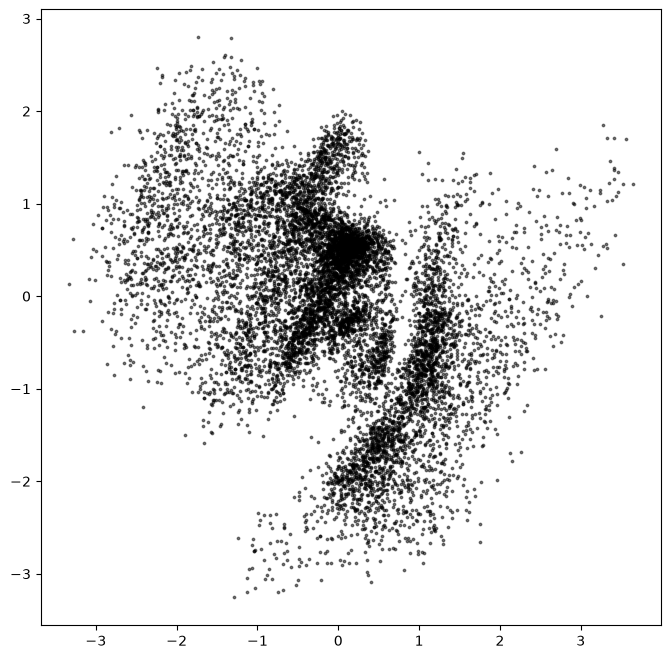

In [19]:
# Show the encoded points in 2D space
figsize = 8

plt.figure(figsize=(figsize, figsize))
plt.scatter(z[:, 0], z[:, 1], c="black", alpha=0.5, s=3)
plt.show()

## 5. Generate using the decoder <a name="decode"></a>

In [20]:
# Sample some points in the latent space, from the standard normal distribution
grid_width, grid_height = (4, 4)
z_sample = np.random.normal(size=(grid_width * grid_height, EMBEDDING_DIM))

In [21]:
# Decode the sampled points
reconstructions = decoder.predict(z_sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


In [22]:
# Convert original embeddings and sampled embeddings to p-values
p = norm.cdf(z)
p_sample = norm.cdf(z_sample)

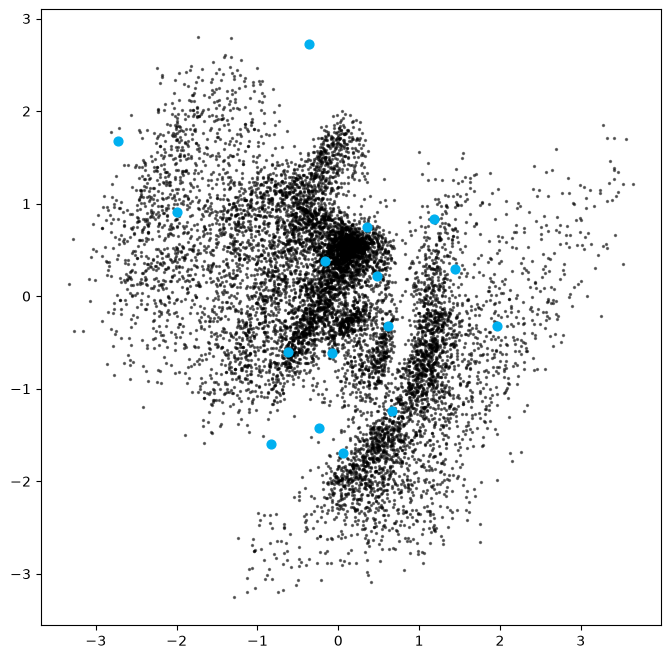

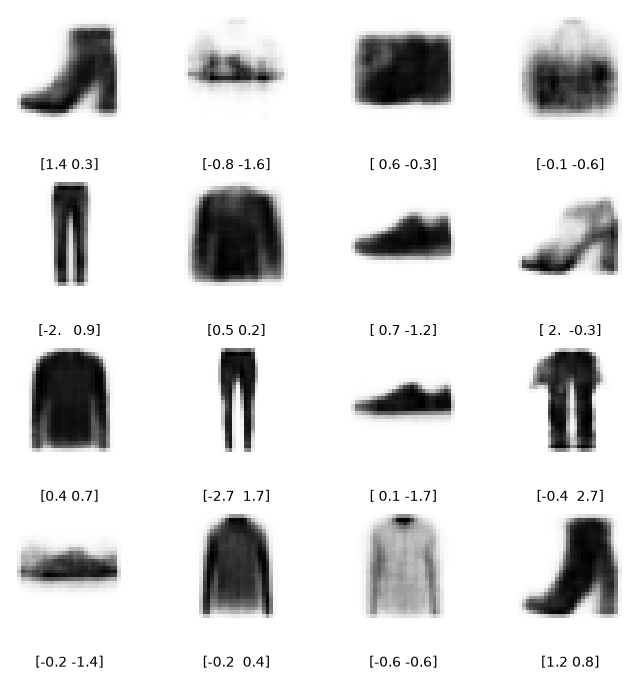

In [23]:
# Draw a plot of...
figsize = 8
plt.figure(figsize=(figsize, figsize))

# ... the original embeddings ...
plt.scatter(z[:, 0], z[:, 1], c="black", alpha=0.5, s=2)

# ... and the newly generated points in the latent space
plt.scatter(z_sample[:, 0], z_sample[:, 1], c="#00B0F0", alpha=1, s=40)
plt.show()

# Add underneath a grid of the decoded images
fig = plt.figure(figsize=(figsize, grid_height * 2))
fig.subplots_adjust(hspace=0.4, wspace=0.4)

for i in range(grid_width * grid_height):
    ax = fig.add_subplot(grid_height, grid_width, i + 1)
    ax.axis("off")
    ax.text(
        0.5,
        -0.35,
        str(np.round(z_sample[i, :], 1)),
        fontsize=10,
        ha="center",
        transform=ax.transAxes,
    )
    ax.imshow(reconstructions[i, :, :], cmap="Greys")

## 6. Explore the latent space <a name="explore"></a>

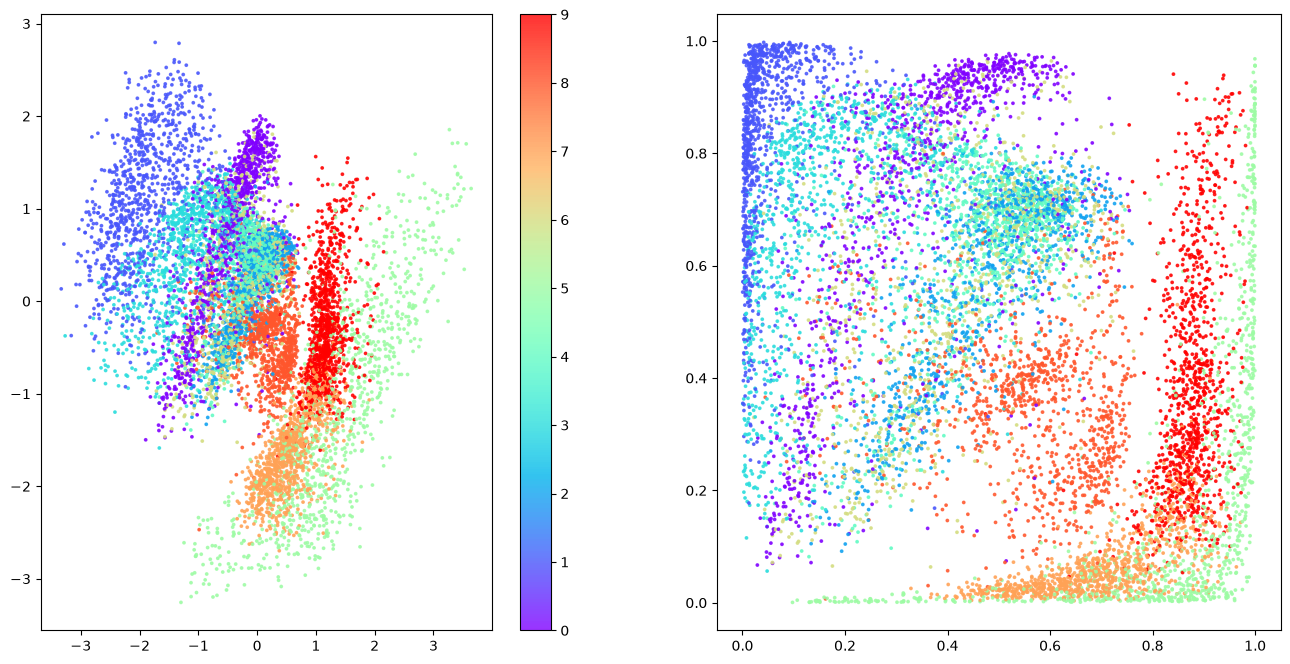

In [24]:
# Colour the embeddings by their label (clothing type - see table)
figsize = 8
fig = plt.figure(figsize=(figsize * 2, figsize))
ax = fig.add_subplot(1, 2, 1)
plot_1 = ax.scatter(
    z[:, 0], z[:, 1], cmap="rainbow", c=example_labels, alpha=0.8, s=3
)
plt.colorbar(plot_1)
ax = fig.add_subplot(1, 2, 2)
plot_2 = ax.scatter(
    p[:, 0], p[:, 1], cmap="rainbow", c=example_labels, alpha=0.8, s=3
)
plt.show()

| ID | Clothing Label |
| :- | :- |
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


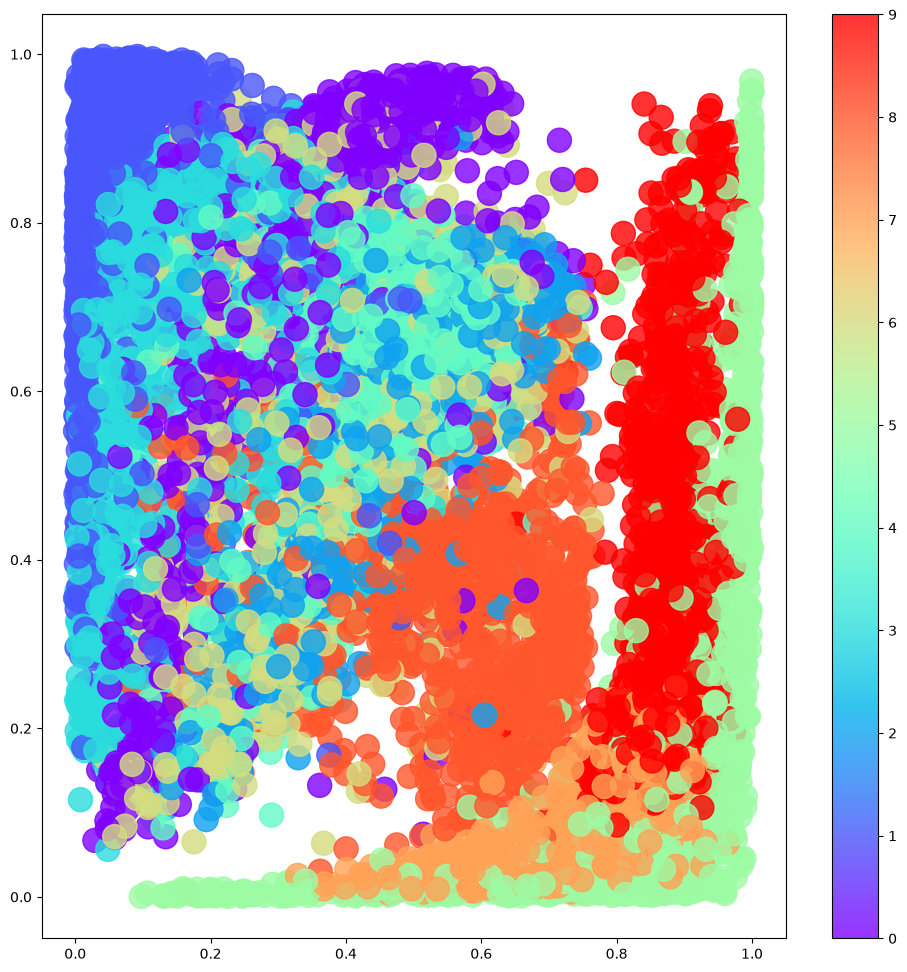

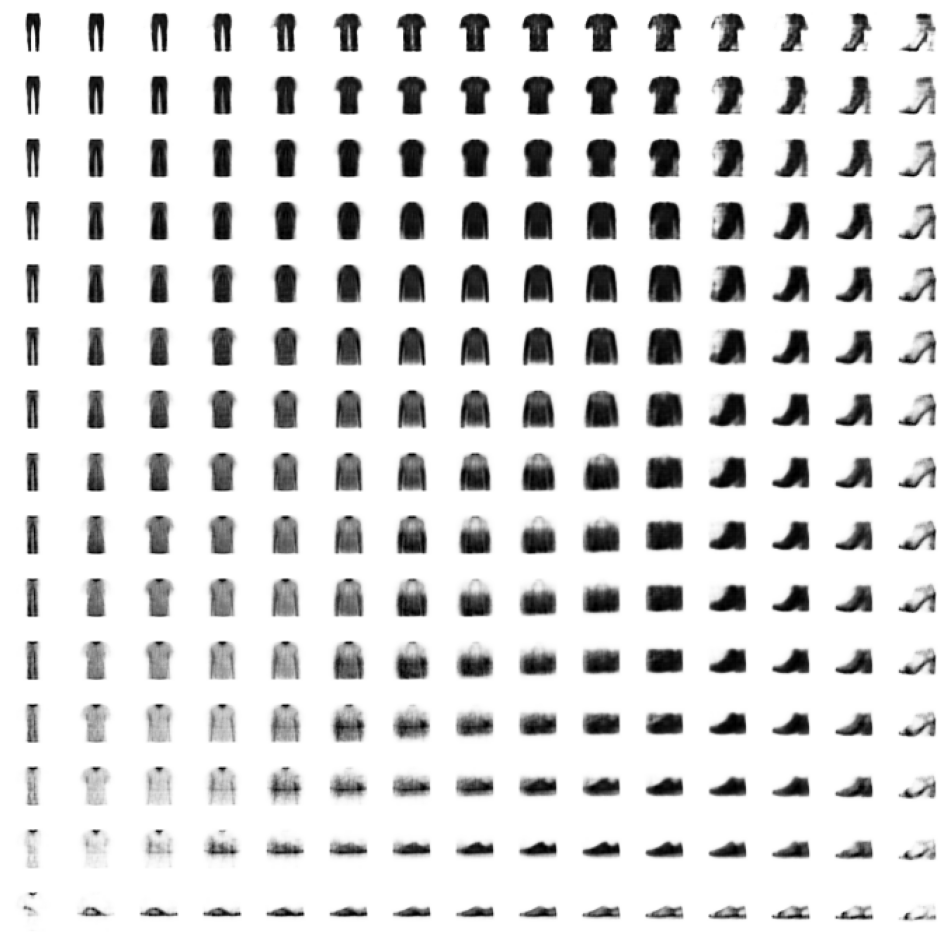

In [25]:
# Colour the embeddings by their label (clothing type - see table)
figsize = 12
grid_size = 15
plt.figure(figsize=(figsize, figsize))
plt.scatter(
    p[:, 0], p[:, 1], cmap="rainbow", c=example_labels, alpha=0.8, s=300
)
plt.colorbar()

x = norm.ppf(np.linspace(0.01, 0.99, grid_size))
y = norm.ppf(np.linspace(0.99, 0.01, grid_size))
xv, yv = np.meshgrid(x, y)
xv = xv.flatten()
yv = yv.flatten()
grid = np.array(list(zip(xv, yv)))

reconstructions = decoder.predict(grid)
# plt.scatter(grid[:, 0], grid[:, 1], c="black", alpha=1, s=10)
plt.show()

fig = plt.figure(figsize=(figsize, figsize))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
for i in range(grid_size**2):
    ax = fig.add_subplot(grid_size, grid_size, i + 1)
    ax.axis("off")
    ax.imshow(reconstructions[i, :, :], cmap="Greys")

# Task 2: Latent-Dimension Ablation

In [26]:
#adapt Foster's encoder and decoder definitions to vary the latent dimension
def create_vae(latent_dim):
    EMBEDDING_DIM = latent_dim

    # Encoder
    encoder_input = layers.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 1), name="encoder_input"
    )
    x = layers.Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(
        encoder_input
    )
    x = layers.Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
    x = layers.Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
    shape_before_flattening = K.int_shape(x)[1:]  # the decoder will need this!

    x = layers.Flatten()(x)
    z_mean = layers.Dense(EMBEDDING_DIM, name="z_mean")(x)
    z_log_var = layers.Dense(EMBEDDING_DIM, name="z_log_var")(x)
    z = Sampling()([z_mean, z_log_var])

    encoder = models.Model(encoder_input, [z_mean, z_log_var, z], name="encoder")

    # Decoder
    decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
    x = layers.Dense(int(np.prod(shape_before_flattening)))(decoder_input)
    x = layers.Reshape(shape_before_flattening)(x)
    x = layers.Conv2DTranspose(
        128, (3, 3), strides=2, activation="relu", padding="same"
    )(x)
    x = layers.Conv2DTranspose(
        64, (3, 3), strides=2, activation="relu", padding="same"
    )(x)
    x = layers.Conv2DTranspose(
        32, (3, 3), strides=2, activation="relu", padding="same"
    )(x)
    decoder_output = layers.Conv2D(
        1,
        (3, 3),
        strides=1,
        activation="sigmoid",
        padding="same",
        name="decoder_output",
    )(x)

    decoder = models.Model(decoder_input, decoder_output)

    return VAE(encoder, decoder)

In [27]:
#reuse the baseline and train the other latent dimensions from scratch
for latent_dim in latent_dims[1:]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(random_seed)

    vae_model = create_vae(latent_dim)
    optimizer = optimizers.Adam(learning_rate=0.0005)
    vae_model.compile(optimizer=optimizer)

    print("Latent dimension:", latent_dim)
    history = vae_model.fit(x_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                            shuffle=True, validation_data=(x_test, x_test), verbose=2)

    vae_models[latent_dim] = vae_model
    loss_history[latent_dim] = history.history

Latent dimension: 8
Epoch 1/5
600/600 - 35s - 58ms/step - kl_loss: 8.1220 - reconstruction_loss: 145.5233 - total_loss: 153.6452 - val_kl_loss: 9.1600 - val_reconstruction_loss: 120.9818 - val_total_loss: 130.1418
Epoch 2/5
600/600 - 48s - 80ms/step - kl_loss: 9.3603 - reconstruction_loss: 118.4543 - total_loss: 127.8147 - val_kl_loss: 9.0153 - val_reconstruction_loss: 118.4109 - val_total_loss: 127.4262
Epoch 3/5
600/600 - 50s - 83ms/step - kl_loss: 9.5086 - reconstruction_loss: 116.6790 - total_loss: 126.1877 - val_kl_loss: 9.5099 - val_reconstruction_loss: 117.2497 - val_total_loss: 126.7596
Epoch 4/5
600/600 - 48s - 79ms/step - kl_loss: 9.6156 - reconstruction_loss: 115.7607 - total_loss: 125.3763 - val_kl_loss: 9.5439 - val_reconstruction_loss: 116.4147 - val_total_loss: 125.9586
Epoch 5/5
600/600 - 44s - 74ms/step - kl_loss: 9.7398 - reconstruction_loss: 115.0959 - total_loss: 124.8357 - val_kl_loss: 9.9138 - val_reconstruction_loss: 115.5474 - val_total_loss: 125.4612
Latent dim

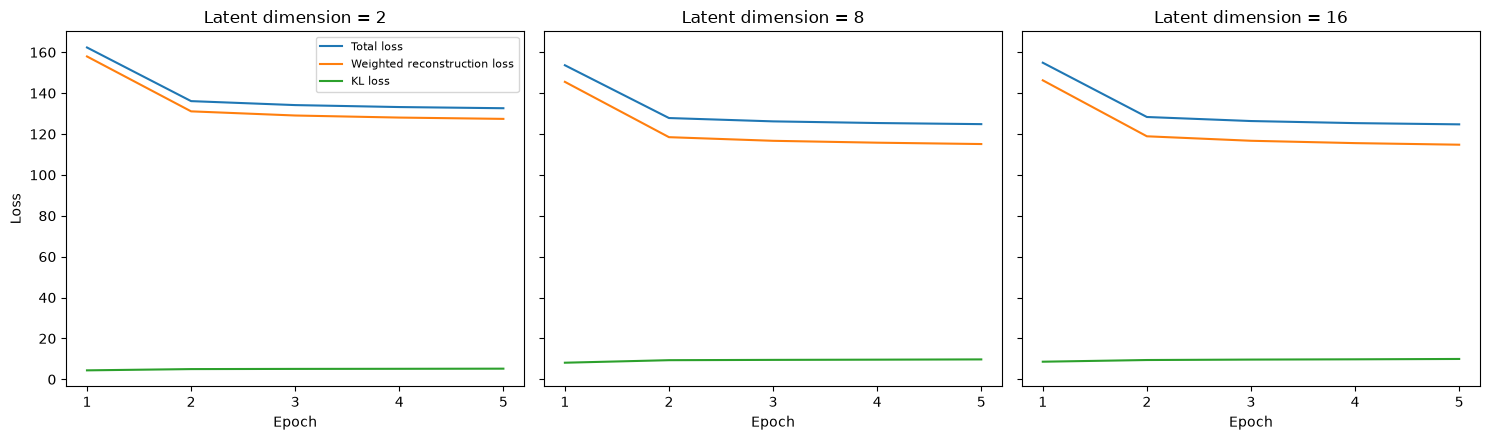

,Latent dimension,Training total loss,Training reconstruction loss,Training KL loss,Validation total loss,Validation reconstruction loss,Validation KL loss
0,2,132.6178,127.4052,5.2126,133.2314,127.8670,5.3643
1,8,124.8357,115.0959,9.7398,125.4612,115.5474,9.9138
2,16,124.7295,114.7724,9.9572,125.1748,115.2179,9.9569


In [28]:
#compare the loss curves with the same vertical scale
figure, axes = plt.subplots(1, len(latent_dims), figsize=(15, 4.5), sharey=True)

for index, latent_dim in enumerate(latent_dims):
    history = loss_history[latent_dim]
    axes[index].plot(epoch_numbers, history["total_loss"], label="Total loss")
    axes[index].plot(epoch_numbers, history["reconstruction_loss"], label="Weighted reconstruction loss")
    axes[index].plot(epoch_numbers, history["kl_loss"], label="KL loss")
    axes[index].set_title("Latent dimension = " + str(latent_dim))
    axes[index].set_xlabel("Epoch")
    axes[index].set_xticks(list(epoch_numbers))

axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

#compare the final training and validation losses
comparison_results = []

for latent_dim in latent_dims:
    history = loss_history[latent_dim]
    comparison_results.append({"Latent dimension": latent_dim,
                               "Training total loss": history["total_loss"][-1],
                               "Training reconstruction loss": history["reconstruction_loss"][-1],
                               "Training KL loss": history["kl_loss"][-1],
                               "Validation total loss": history["val_total_loss"][-1],
                               "Validation reconstruction loss": history["val_reconstruction_loss"][-1],
                               "Validation KL loss": history["val_kl_loss"][-1]})

comparison_results = pd.DataFrame(comparison_results)
comparison_results.round(4)

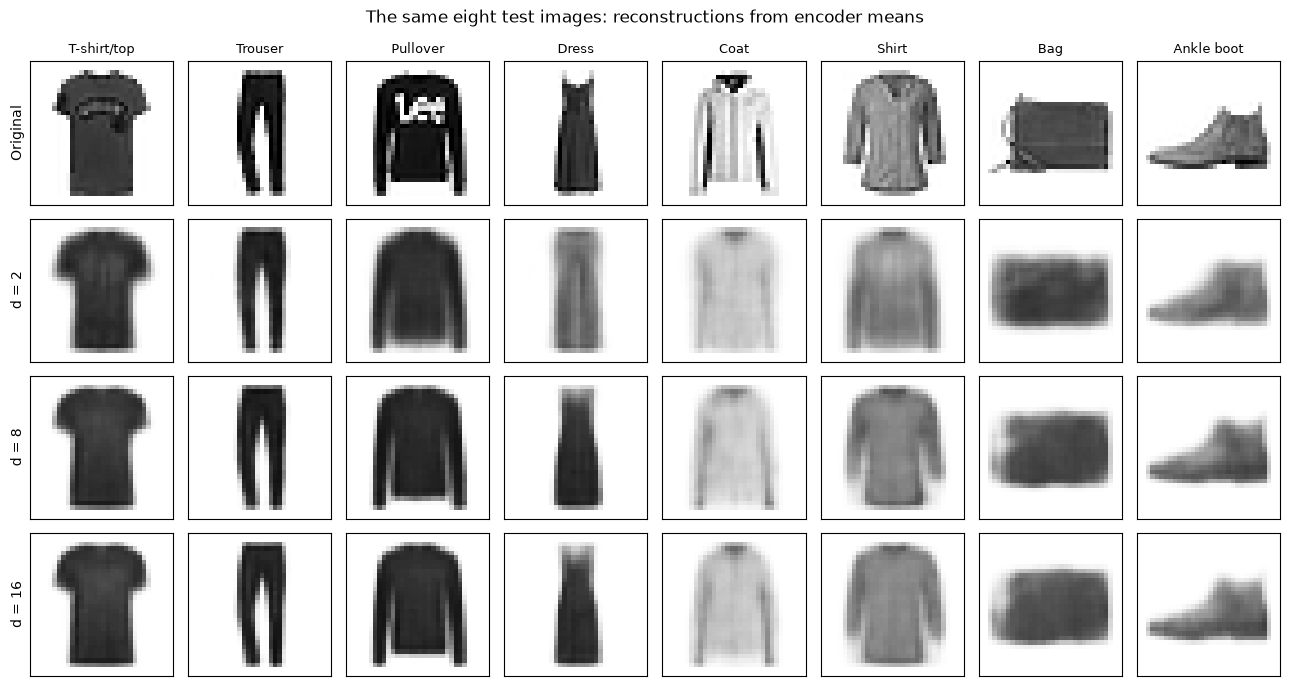

In [29]:
#select the same eight test images for all latent dimensions
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
selected_classes = [0, 1, 2, 3, 4, 6, 8, 9]
test_indices = [np.flatnonzero(y_test == class_label)[0] for class_label in selected_classes]
test_images = x_test[test_indices]

#use encoder means for a fixed reconstruction of each test image
mean_encoders = {}
reconstructions = {}

for latent_dim in latent_dims:
    encoder = vae_models[latent_dim].encoder
    mean_encoders[latent_dim] = models.Model(encoder.input, encoder.outputs[0])
    z_mean = mean_encoders[latent_dim].predict(test_images, verbose=0)
    reconstructions[latent_dim] = vae_models[latent_dim].decoder.predict(z_mean, verbose=0)

figure, axes = plt.subplots(len(latent_dims) + 1, 8, figsize=(13, 7))
image_rows = [test_images] + [reconstructions[latent_dim] for latent_dim in latent_dims]
row_labels = ["Original"] + ["d = " + str(latent_dim) for latent_dim in latent_dims]

for row, images in enumerate(image_rows):
    for column, image in enumerate(images):
        axes[row, column].imshow(image[:, :, 0], cmap="gray_r", vmin=0, vmax=1)
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
        if row == 0:
            axes[row, column].set_title(class_names[y_test[test_indices[column]]], fontsize=9)
        if column == 0:
            axes[row, column].set_ylabel(row_labels[row])

plt.suptitle("The same eight test images: reconstructions from encoder means")
plt.tight_layout()
plt.show()

# Task 3: Sample from the Prior

Best latent dimension: 16


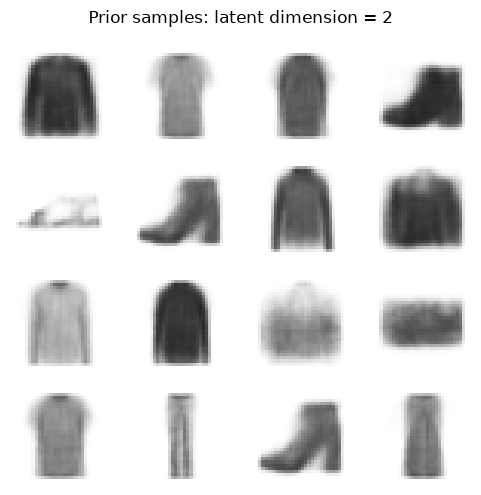

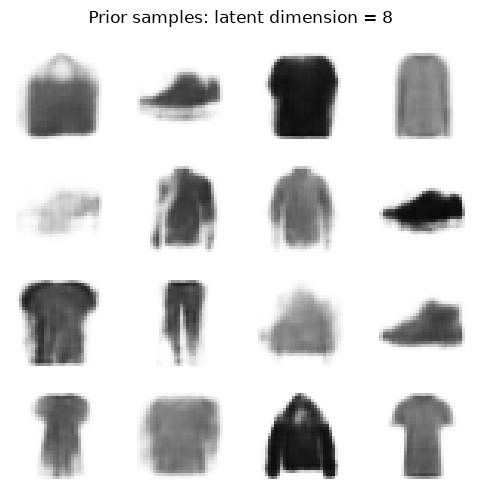

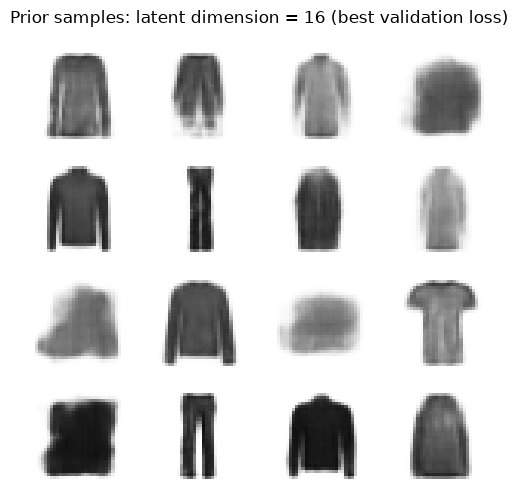

In [30]:
#select the latent dimension with the lowest final validation total loss
best_latent_dim = min(latent_dims,
                      key=lambda latent_dim: loss_history[latent_dim]["val_total_loss"][-1])
print("Best latent dimension:", best_latent_dim)

#draw sixteen prior samples for each latent dimension
np.random.seed(random_seed + 1)
prior_samples = {}

for latent_dim in latent_dims:
    z_samples = np.random.normal(size=(16, latent_dim)).astype("float32")
    generated_images = vae_models[latent_dim].decoder.predict(z_samples, verbose=0)
    prior_samples[latent_dim] = generated_images

    figure, axes = plt.subplots(4, 4, figsize=(5, 5))
    for axis, image in zip(axes.flat, generated_images):
        axis.imshow(image[:, :, 0], cmap="gray_r", vmin=0, vmax=1)
        axis.axis("off")

    title = "Prior samples: latent dimension = " + str(latent_dim)
    if latent_dim == best_latent_dim:
        title += " (best validation loss)"

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Task 4: Latent-Space Visualization

Latent dimension: 2 Encoder means shape: (10000, 2)
Latent dimension: 8 Encoder means shape: (10000, 8)
Latent dimension: 16 Encoder means shape: (10000, 16)


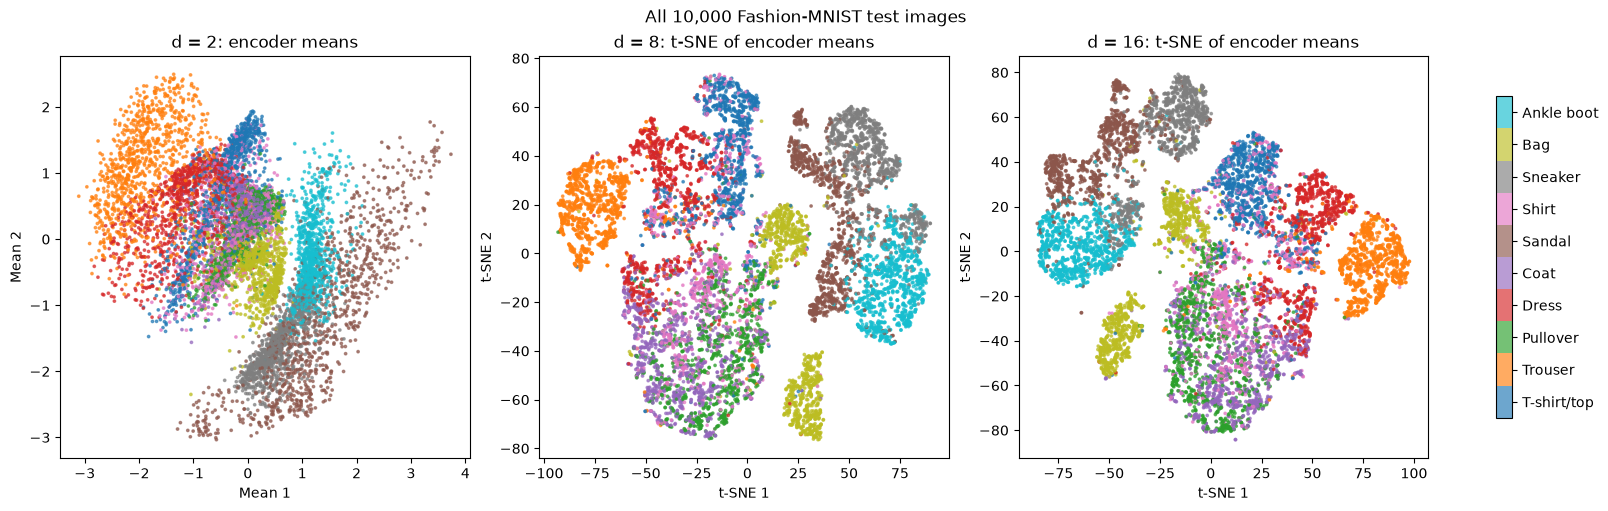

In [31]:
#encode all test images and retain the encoder means
encoder_means = {}

for latent_dim in latent_dims:
    encoder_means[latent_dim] = mean_encoders[latent_dim].predict(x_test, batch_size=BATCH_SIZE, verbose=0)
    print("Latent dimension:", latent_dim, "Encoder means shape:", encoder_means[latent_dim].shape)

#use the two-dimensional means directly and project larger latent spaces
latent_points = {}

for latent_dim in latent_dims:
    z_mean = encoder_means[latent_dim]
    if latent_dim == 2:
        latent_points[latent_dim] = z_mean
    else:
        tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
                    max_iter=1000, random_state=random_seed, n_jobs=1)
        latent_points[latent_dim] = tsne.fit_transform(z_mean)

#color all test encoder means by class label
figure, axes = plt.subplots(1, len(latent_dims), figsize=(16, 5), constrained_layout=True)

for index, latent_dim in enumerate(latent_dims):
    points = latent_points[latent_dim]
    scatter = axes[index].scatter(points[:, 0], points[:, 1], c=y_test,
                                  cmap="tab10", vmin=-0.5, vmax=9.5, s=3, alpha=0.65)
    if latent_dim == 2:
        axes[index].set_title("d = 2: encoder means")
        axes[index].set_xlabel("Mean 1")
        axes[index].set_ylabel("Mean 2")
    else:
        axes[index].set_title("d = " + str(latent_dim) + ": t-SNE of encoder means")
        axes[index].set_xlabel("t-SNE 1")
        axes[index].set_ylabel("t-SNE 2")

colorbar = figure.colorbar(scatter, ax=list(axes), ticks=range(10), shrink=0.8)
colorbar.ax.set_yticklabels(class_names)
figure.suptitle("All 10,000 Fashion-MNIST test images")
plt.show()